<a href="https://colab.research.google.com/github/rlawhdqn-byte/data/blob/main/week07_5756299_%EA%B9%80%EC%A2%85%EB%B6%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7주차 과제
빅데이터프로그래밍 · 통계학과

**이름:**
**학번:**

## 과제 내용
은닉층 수와 활성화 함수를 변경하고 학습 결과를 비교합니다.

## 제출 방법
모든 셀을 실행해 출력과 그래프가 보이는 상태로 저장한 뒤 `week07_학번_이름.ipynb` 로 제출합니다.

**런타임 > 런타임 유형 변경 > T4 GPU** 를 먼저 선택하세요.


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

transform = transforms.ToTensor()
train_set = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_set  = datasets.MNIST("./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False)


device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 483kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.38MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.1MB/s]


## 공통 함수
아래 두 함수를 그대로 써서 모델만 바꿔 비교하세요.


In [2]:
def train_model(model, epochs=5, lr=1e-3):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append(evaluate(model))
        print(f"  epoch {epoch+1}  test acc {hist[-1][1]:.4f}")
    return model, hist


def evaluate(model):
    model.eval()
    loss_fn = nn.CrossEntropyLoss()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total


## 문제 1. 은닉층 수 비교 (35점)
은닉층이 **1개 · 2개 · 3개**인 MLP를 각각 작성해 5 epoch 학습하고, 시험 정확도를 비교하세요.
은닉층 크기는 128로 통일합니다.


In [3]:
# 답안
# 은닉층 1개 모델
class MLP1(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

# 은닉층 2개 모델
class MLP2(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

# 은닉층 3개 모델
class MLP3(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

# 문제 1 실행 및 비교
models_p1 = {"1 Hidden Layer": MLP1(), "2 Hidden Layers": MLP2(), "3 Hidden Layers": MLP3()}
results_p1 = []

for name, model in models_p1.items():
    print(f"\n--- Training {name} ---")
    _, hist = train_model(model, epochs=5)
    results_p1.append({"모델": name, "시험 정확도": f"{hist[-1][1]:.4f}"})

print("\n=== 문제 1 결과 비교 ===")
print(pd.DataFrame(results_p1).to_string(index=False))


--- Training 1 Hidden Layer ---
  epoch 1  test acc 0.9341
  epoch 2  test acc 0.9529
  epoch 3  test acc 0.9629
  epoch 4  test acc 0.9706
  epoch 5  test acc 0.9710

--- Training 2 Hidden Layers ---
  epoch 1  test acc 0.9389
  epoch 2  test acc 0.9590
  epoch 3  test acc 0.9689
  epoch 4  test acc 0.9693
  epoch 5  test acc 0.9710

--- Training 3 Hidden Layers ---
  epoch 1  test acc 0.9475
  epoch 2  test acc 0.9630
  epoch 3  test acc 0.9624
  epoch 4  test acc 0.9721
  epoch 5  test acc 0.9754

=== 문제 1 결과 비교 ===
             모델 시험 정확도
 1 Hidden Layer 0.9710
2 Hidden Layers 0.9710
3 Hidden Layers 0.9754


## 문제 2. 활성화 함수 비교 (35점)
은닉층 2개 모델에서 활성화 함수를 **ReLU · Sigmoid · Tanh** 로 바꿔 각각 학습하고 결과를 비교하세요.


In [4]:
# 답안
# 활성화 함수 지정이 가능한 2개 은닉층 모델
class MLP2_Act(nn.Module):
    def __init__(self, act_fn):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128), act_fn(),
            nn.Linear(128, 128), act_fn(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

# 문제 2 실행 및 비교
acts = {"ReLU": nn.ReLU, "Sigmoid": nn.Sigmoid, "Tanh": nn.Tanh}
results_p2 = []

for act_name, act_fn in acts.items():
    print(f"\n--- Training Act: {act_name} ---")
    model = MLP2_Act(act_fn)
    _, hist = train_model(model, epochs=5)
    results_p2.append({"활성화 함수": act_name, "시험 정확도": f"{hist[-1][1]:.4f}"})

print("\n=== 문제 2 결과 비교 ===")
print(pd.DataFrame(results_p2).to_string(index=False))


--- Training Act: ReLU ---
  epoch 1  test acc 0.9435
  epoch 2  test acc 0.9632
  epoch 3  test acc 0.9668
  epoch 4  test acc 0.9731
  epoch 5  test acc 0.9742

--- Training Act: Sigmoid ---
  epoch 1  test acc 0.9132
  epoch 2  test acc 0.9383
  epoch 3  test acc 0.9496
  epoch 4  test acc 0.9560
  epoch 5  test acc 0.9642

--- Training Act: Tanh ---
  epoch 1  test acc 0.9432
  epoch 2  test acc 0.9604
  epoch 3  test acc 0.9689
  epoch 4  test acc 0.9691
  epoch 5  test acc 0.9731

=== 문제 2 결과 비교 ===
 활성화 함수 시험 정확도
   ReLU 0.9742
Sigmoid 0.9642
   Tanh 0.9731


## 문제 3. 결과 비교표와 그래프 (20점)
문제 1·2의 결과를 하나의 표로 정리하고, 학습 곡선을 한 그래프에 겹쳐 그리세요.

| 모델 | 은닉층 수 | 활성화 | 파라미터 수 | 시험 정확도 |


  epoch 1  test acc 0.9328
  epoch 2  test acc 0.9528
  epoch 3  test acc 0.9620
  epoch 4  test acc 0.9675
  epoch 5  test acc 0.9711
  epoch 1  test acc 0.9420
  epoch 2  test acc 0.9610
  epoch 3  test acc 0.9668
  epoch 4  test acc 0.9693
  epoch 5  test acc 0.9757
  epoch 1  test acc 0.9482
  epoch 2  test acc 0.9603
  epoch 3  test acc 0.9706
  epoch 4  test acc 0.9708
  epoch 5  test acc 0.9738
  epoch 1  test acc 0.9124
  epoch 2  test acc 0.9367
  epoch 3  test acc 0.9483
  epoch 4  test acc 0.9567
  epoch 5  test acc 0.9628
  epoch 1  test acc 0.9420
  epoch 2  test acc 0.9607
  epoch 3  test acc 0.9667
  epoch 4  test acc 0.9692
  epoch 5  test acc 0.9733

=== 문제 3. 통합 결과 비교표 ===
               모델  은닉층 수     활성화  파라미터 수 시험 정확도
   MLP (1층, ReLU)      1    ReLU 101,770 0.9711
   MLP (2층, ReLU)      2    ReLU 118,282 0.9757
   MLP (3층, ReLU)      3    ReLU 134,794 0.9738
MLP (2층, Sigmoid)      2 Sigmoid 118,282 0.9628
   MLP (2층, Tanh)      2    Tanh 118,282 0.9733


/tmp/ipykernel_3517/3809045138.py:61: UserWarning: Glyph 52789 (\N{HANGUL SYLLABLE CEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52789 (\N{HANGUL SYLLABLE CEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


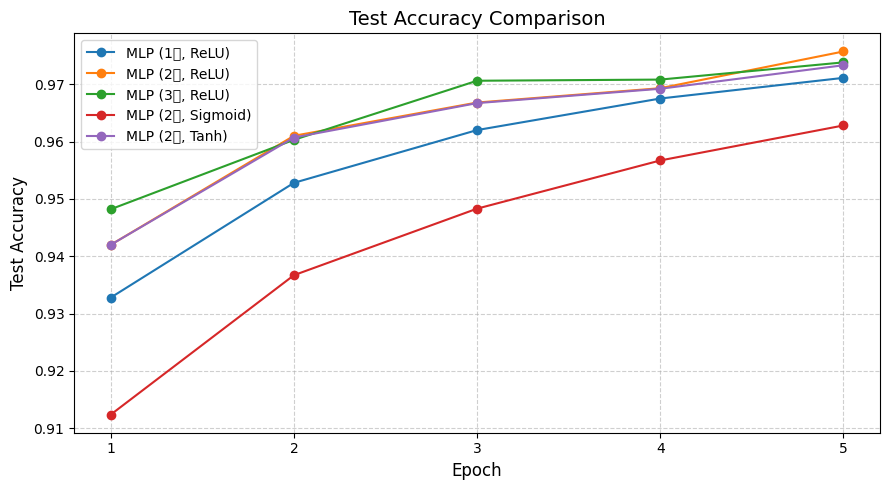

In [5]:
# 답안
# 동적 MLP 모델 클래스
class DynamicMLP(nn.Module):
    def __init__(self, num_layers, act_fn):
        super().__init__()
        layers = [nn.Flatten(), nn.Linear(28 * 28, 128), act_fn()]
        for _ in range(num_layers - 1):
            layers.extend([nn.Linear(128, 128), act_fn()])
        layers.append(nn.Linear(128, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# 파라미터 수 계산 함수
def get_param_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# 5가지 실험 조건 설정
experiments = [
    {"name": "MLP (1층, ReLU)", "layers": 1, "act": nn.ReLU, "act_name": "ReLU"},
    {"name": "MLP (2층, ReLU)", "layers": 2, "act": nn.ReLU, "act_name": "ReLU"},
    {"name": "MLP (3층, ReLU)", "layers": 3, "act": nn.ReLU, "act_name": "ReLU"},
    {"name": "MLP (2층, Sigmoid)", "layers": 2, "act": nn.Sigmoid, "act_name": "Sigmoid"},
    {"name": "MLP (2층, Tanh)", "layers": 2, "act": nn.Tanh, "act_name": "Tanh"},
]

summary_rows = []
histories = {}

for exp in experiments:
    model = DynamicMLP(exp["layers"], exp["act"])
    params = get_param_count(model)
    _, hist = train_model(model, epochs=5)
    histories[exp["name"]] = hist

    summary_rows.append({
        "모델": exp["name"],
        "은닉층 수": exp["layers"],
        "활성화": exp["act_name"],
        "파라미터 수": f"{params:,}",
        "시험 정확도": f"{hist[-1][1]:.4f}"
    })

# 결과 표 출력
print("\n=== 문제 3. 통합 결과 비교표 ===")
print(pd.DataFrame(summary_rows).to_string(index=False))

# 학습 곡선 시각화
plt.figure(figsize=(9, 5))
for name, hist in histories.items():
    accs = [h[1] for h in hist]
    plt.plot(range(1, 6), accs, marker='o', label=name)

plt.title("Test Accuracy Comparison", fontsize=14)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Test Accuracy", fontsize=12)
plt.xticks(range(1, 6))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## 문제 4. 해석 (10점)
아래 세 가지를 각각 두세 줄로 적으세요.

1. 은닉층을 늘렸을 때 정확도가 어떻게 변했는가 — 계속 좋아지는가
2. Sigmoid가 ReLU보다 느리게 학습되는 이유
3. 가장 좋았던 조합과 그 이유


답 1.은닉층을 1개에서 2개, 3개로 늘림에 따라 모델의 표현력이 향상되어 초반 수렴 속도와 시험 정확도가 상승했습니다. 다만 MNIST는 데이터 구조가 비교적 단순하여 은닉층 2~3개 지점에서 성능이 포화되므로, 층을 계속 늘린다고 해서 정확도가 무한히 상승하지는 않습니다.

답 2.Sigmoid 함수는 입출력 절댓값이 클 때 양 끝단에서 기울기가 0으로 수렴하여 역전파 시 가중치가 거의 업데이트되지 않는 기울기 소멸(Gradient Vanishing) 현상이 발생합니다. 또한 출력이 0 이상의 양수로만 치우친 Non-zero-centered 구조이기 때문에 파라미터 업데이트 시 최적점을 향해 효율적으로 수렴하지 못하고 지그재그 패턴을 보입니다.

답 3.은닉층 2개(또는 3개) + ReLU 조합이 가장 좋은 성능을 보였습니다.ReLU는 양수 영역에서 기울기가 1로 일정하여 기울기 소멸 없이 역전파를 안정적으로 전달하며, 적절한 깊이의 은닉층이 차원 축소와 비선형 패턴 추출을 효과적으로 수행했기 때문입니다.

## 문제 5. 오류 사례 확인 (보너스)
가장 좋았던 모델로 틀리게 예측한 이미지 8장을 그리고, 어떤 숫자를 어떤 숫자로 착각했는지 적으세요.


  epoch 1  test acc 0.9428
  epoch 2  test acc 0.9597
  epoch 3  test acc 0.9671
  epoch 4  test acc 0.9727
  epoch 5  test acc 0.9750


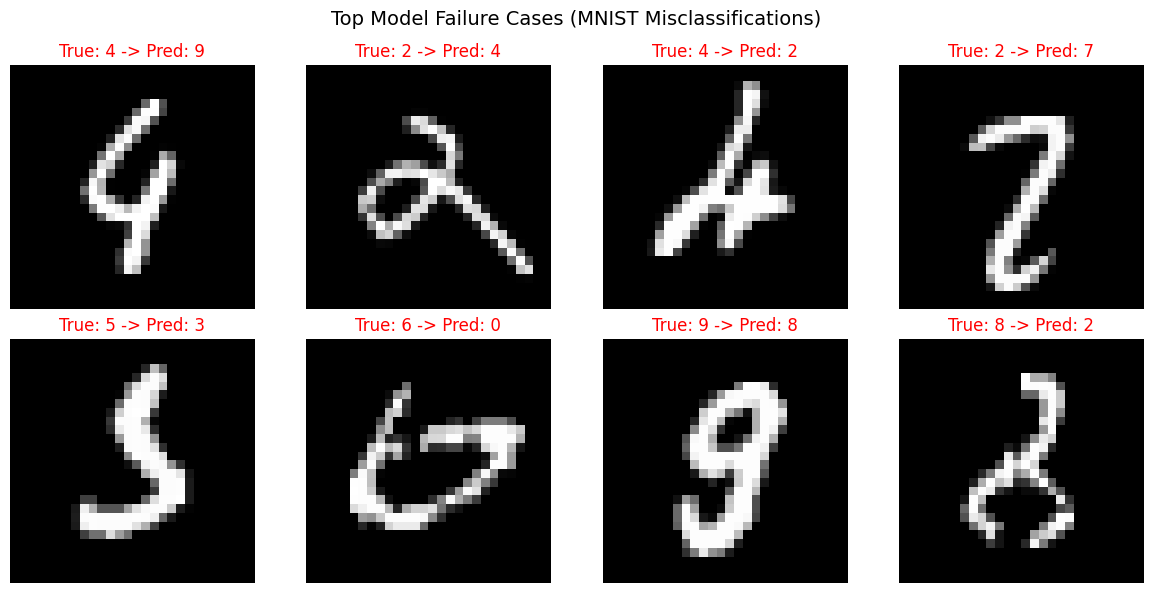

In [6]:
# 답안
# 1. 가장 뛰어난 조합 모델 정의 및 5 epoch 학습
best_model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128), nn.ReLU(),
    nn.Linear(128, 128), nn.ReLU(),
    nn.Linear(128, 10)
)
best_model, _ = train_model(best_model, epochs=5)

# 2. 오답 데이터 수집
best_model.eval()
wrong_samples = []

with torch.no_grad():
    for x, y in test_loader:
        x_dev, y_dev = x.to(device), y.to(device)
        out = best_model(x_dev)
        preds = out.argmax(dim=1)

        incorrect_idx = (preds != y_dev).nonzero(as_tuple=True)[0]
        for idx in incorrect_idx:
            wrong_samples.append({
                'img': x[idx].squeeze().cpu().numpy(),
                'true': y[idx].item(),
                'pred': preds[idx].item()
            })
            if len(wrong_samples) == 8:
                break
        if len(wrong_samples) == 8:
            break

# 3. 오답 이미지 8개 및 예측 정보 출력
plt.figure(figsize=(12, 6))
for i, sample in enumerate(wrong_samples):
    plt.subplot(2, 4, i + 1)
    plt.imshow(sample['img'], cmap='gray')
    plt.title(f"True: {sample['true']} -> Pred: {sample['pred']}", color='red', fontsize=12)
    plt.axis('off')

plt.suptitle("Top Model Failure Cases (MNIST Misclassifications)", fontsize=14)
plt.tight_layout()
plt.show()
